# Outlier Treatment

## 1. What Is an Outlier?

An outlier is a data point that is unusually far from most other observations in a dataset.

For example, consider these employee salaries:

`25000, 28000, 30000, 32000, 35000, 400000`

Most salaries are between 25,000 and 35,000, but one salary is 400,000. This value may be an outlier because it is much larger than the others.

However, an unusual value is not necessarily incorrect. The salary of 400,000 could belong to a senior executive.

**Important:** An outlier is a value that deserves investigation, not automatically a value that must be deleted.

## 2. Outlier vs Error

An outlier is an unusually extreme observation. An error is an incorrect value caused by a data-entry mistake, measurement problem, or other issue.

| Outlier                                          | Error                                                     |
| ------------------------------------------------ | --------------------------------------------------------- |
| An unusually high or low observation             | An incorrect or unreliable observation                    |
| Can be valid or invalid                          | Usually requires correction or investigation              |
| May contain useful information                   | Can reduce data quality                                   |
| May be retained, capped, transformed, or removed | Should be corrected or handled based on reliable evidence |

**Example 1 – Valid outlier:**

A customer's annual spending is ₹500,000 while most customers spend less than ₹50,000. The customer may genuinely be a high-value customer.

**Example 2 – Possible error:**

An employee's age is recorded as 250. This value is likely incorrect and should be investigated.

An outlier detection method cannot determine by itself whether a value is an error. We must also consider business rules, the original data source, and domain knowledge.

## 3. Why Is Outlier Treatment Important?

Outlier treatment is important because extreme values can affect:

* Mean and standard deviation.
* Statistical analysis.
* Data visualizations.
* Feature scaling.
* Regression models.
* Distance-based algorithms such as K-Nearest Neighbors.
* Clustering algorithms such as K-Means.

However, tree-based algorithms are generally less sensitive to the scale of numerical features than distance-based models. Extreme values can still influence their learned splits.

The appropriate treatment depends on the data and the Machine Learning problem.

## 4. IQR Method

IQR stands for Interquartile Range. It measures the spread of the middle 50% of the data.

* Q1: 25th percentile.
* Q3: 75th percentile.
* IQR: Q3 minus Q1.

The standard IQR method identifies potential outliers using these boundaries:

* Lower boundary = Q1 − 1.5 × IQR
* Upper boundary = Q3 + 1.5 × IQR

Values outside these boundaries are flagged as potential outliers.

**Example:**

Suppose:

* Q1 = 20
* Q3 = 40
* IQR = 20

Then:

* Lower boundary = 20 − (1.5 × 20) = -10
* Upper boundary = 40 + (1.5 × 20) = 70

Values below -10 or above 70 are flagged.

The IQR method is useful when the data is skewed because it is less affected by extreme values than the mean and standard deviation.

## 5. Z-Score Method

A Z-score measures how many standard deviations a value is away from the mean.

A common rule is to flag values with an absolute Z-score greater than 3 as potential outliers.

For example, a Z-score of 3 means the observation is three standard deviations above the mean.

**When is it useful?**

* When numerical data is approximately normally distributed.
* When the mean and standard deviation provide a meaningful description of the data.

**Limitation:** The mean and standard deviation can be strongly affected by extreme observations. The ±3 threshold is a guideline, not a universal rule.

## 6. Percentile Method

The percentile method identifies extreme values using selected percentiles.

For example:

* Values below the 1st percentile may be flagged as unusually low.
* Values above the 99th percentile may be flagged as unusually high.

This method is useful when we want to identify or limit extreme values based on the distribution of the data.

However, the chosen percentiles depend on the business problem. A value above the 99th percentile is not necessarily an error.

## 7. Winsorization

Winsorization limits extreme values by replacing them with selected percentile boundary values.

For example, if the upper limit is the 95th percentile, values above that limit are replaced with the 95th-percentile value.

Original values:

`10, 12, 15, 18, 20, 100`

Suppose the chosen upper boundary is 20.

After upper-tail Winsorization:

`10, 12, 15, 18, 20, 20`

The extreme value is retained as an observation, but its magnitude is limited.

**Advantage:** Reduces the influence of extreme values without deleting records.

**Limitation:** Changes the original values and may hide meaningful extremes.

## 8. Capping

Capping replaces values above a selected upper boundary with that boundary.

Example:

Original salaries:

`25000, 30000, 35000, 400000`

If the selected upper cap is 100000, the result is:

`25000, 30000, 35000, 100000`

Capping is useful when extreme values are valid but their influence needs to be limited.

## 9. Flooring

Flooring replaces values below a selected lower boundary with that boundary.

Example:

Original values:

`-100, 10, 20, 30`

If the lower floor is 0, the result is:

`0, 10, 20, 30`

Flooring should only be applied when the chosen boundary makes sense for the variable.

For example, negative quantities may be invalid for some business situations, but negative temperatures or account balances may be valid.

## 10. Transformation

A transformation changes the scale or distribution of numerical data.

Common transformations include:

* Log transformation.
* Square-root transformation.
* Power transformation.
* Box-Cox transformation.
* Yeo-Johnson transformation.

**Example:**

Income data often contains many moderate values and a few very high values. A log transformation can reduce right skew and make the distribution less dominated by large values.

A log transformation cannot be directly applied to negative values, and ordinary logarithms cannot be applied to zero. Suitable alternatives or adjustments must be chosen carefully.

The Yeo-Johnson transformation can handle zero and negative values.

**Important:** Transformation changes the scale of values; it does not prove that the original values were errors.

## 11. Removing Outliers

Removing an outlier means deleting the observation from the dataset.

Removal may be appropriate when:

* The value is confirmed to be an error.
* The record is impossible under reliable business rules.
* The observation is corrupted and cannot be recovered.
* There is a documented reason that exclusion is appropriate for the analysis.

Removal may be inappropriate when:

* The value is a genuine extreme observation.
* The observation represents an important customer or business case.
* The value is rare but relevant to the target problem.
* Removing it would create bias or discard important information.

Before removing a record, investigate the reason and document the decision.

## 12. Retaining Outliers

Retaining an outlier means keeping the original observation without changing its value.

Retention may be appropriate when:

* The observation is genuine.
* The extreme value is important to the business.
* The model must learn from rare events.
* The selected algorithm can handle the value appropriately.

For example, fraud detection often requires retaining unusual transactions because these observations may be important for identifying fraud.

## 13. How Do We Choose the Right Treatment?

For every detected outlier, ask:

1. Is the value an error?
2. Is it a valid extreme observation?
3. Can the original value be verified?
4. Should it be corrected?
5. Should it be removed?
6. Should it be capped or floored?
7. Should it be transformed?
8. Should it be retained?
9. Why is the selected treatment appropriate?

| Situation                                               | Possible treatment                               |
| ------------------------------------------------------- | ------------------------------------------------ |
| Confirmed data-entry error                              | Correct using reliable source information        |
| Impossible value                                        | Investigate and correct or mark invalid          |
| Valid but extremely high value                          | Retain, cap, or transform based on the objective |
| Right-skewed numerical feature                          | Consider a suitable transformation               |
| Rare but important fraud transaction                    | Usually retain for fraud analysis                |
| Extreme value with little influence on the chosen model | Retain if justified                              |

These are possible decisions, not automatic rules.

## 14. Outlier Treatment in Machine Learning

Outlier treatment should be based on the feature, the business context, and the model.

For a Machine Learning workflow:

1. Inspect the distribution of numerical features.
2. Detect potential outliers.
3. Investigate whether the values are valid.
4. Select an appropriate treatment.
5. Fit any learned thresholds using training data only.
6. Apply the same learned treatment to validation and test data.
7. Compare model performance and data quality before and after treatment.

**Key takeaway:** Outlier detection identifies unusual values. Outlier treatment decides what to do with them. These are two different steps.


# Demonstration of the Concept – Outlier Treatment

## Real-World Example: Customer Spending Analysis

Imagine an online shopping company wants to understand customer spending and build a Machine Learning model to predict future purchases.

The dataset contains the following monthly spending values:

`1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 3500, 50000`

Most customers spend between 1,200 and 3,500, but one customer spends 50,000.

This value may be an outlier because it is much higher than the other observations.

However, the customer might be a genuine high-value customer. We should not automatically remove the record.

## 1. Detect Potential Outliers Using IQR

The IQR method calculates the first quartile, third quartile, and interquartile range.

It then calculates the lower and upper boundaries.

Any spending value outside these boundaries is flagged as a potential outlier.

The result identifies unusual values, but it does not tell us whether the values are errors.

## 2. Detect Potential Outliers Using Z-Score

The Z-score method measures the distance between an observation and the mean in standard deviation units.

A common threshold is an absolute Z-score greater than 3.

This method is useful when the feature's distribution is approximately normal, but it may be less suitable for strongly skewed spending data.

## 3. Detect Potential Outliers Using Percentiles

We can inspect the 1st and 99th percentiles to understand the extreme ends of the spending distribution.

Values outside these limits can be flagged for further investigation.

The percentile boundaries depend on the dataset and business requirements.

## 4. Compare Different Treatment Methods

Suppose we investigate the spending value of 50,000.

We discover that the transaction is genuine and represents a high-value customer.

Possible decisions include:

### Option A: Retain the Outlier

Keep the value as 50,000.

This is appropriate if the value is valid and the analysis needs to represent high-value customers accurately.

### Option B: Cap the Outlier

Replace 50,000 with a selected upper limit.

This may be useful if extreme values have an undesirable influence on a particular model. However, the selected cap must be justified.

### Option C: Transform the Feature

Apply a suitable transformation, such as a logarithmic transformation, to reduce right skew.

This can help some models learn patterns across a wide range of spending values.

### Option D: Remove the Outlier

Delete the observation only if there is a justified reason, such as a confirmed data error or a clearly defined exclusion rule.

Removing a genuine high-value customer simply because the value is unusual could bias the analysis.

### Option E: Apply Winsorization

Replace values beyond a selected percentile boundary with that boundary.

This limits extreme values while keeping the observations in the dataset.

## 5. Outlier Decision Table

| Observation        | Investigation result                                 | Possible decision                  | Reason                                              |
| ------------------ | ---------------------------------------------------- | ---------------------------------- | --------------------------------------------------- |
| Spending = 50,000  | Verified genuine purchase                            | Retain                             | High-value customers are important                  |
| Spending = 500,000 | Extra zero confirmed from source                     | Correct                            | The original source confirms a data-entry error     |
| Spending = 50,000  | Valid but disproportionately influential for a model | Consider capping or transformation | May reduce excessive influence if justified         |
| Spending = 50,000  | Invalid test record with reliable evidence           | Remove or exclude                  | The record does not represent a genuine transaction |

The correct decision depends on the investigation and the objective of the analysis.

## 6. What Should We Learn?

* IQR, Z-score, and percentile methods help identify potential outliers.
* Winsorization, capping, flooring, and transformations can limit or change the influence of extreme values.
* Removing an observation permanently discards that record from the analysis.
* Retaining an outlier preserves the original value.
* Valid extreme values may contain important business information.
* Treatment decisions should be documented and evaluated.

**Important:** The objective is not to make every dataset look uniform. The objective is to prepare reliable data without unnecessarily losing useful information.


Original Dataset:
   Customer_ID  Monthly_Spending
0            1              1200
1            2              1500
2            3              1800
3            4              2000
4            5              2200
5            6              2500
6            7              2800
7            8              3000
8            9              3500
9           10             50000

IQR Results:
Q1: 1850.0
Q3: 2950.0
IQR: 1100.0
Lower Boundary: 200.0
Upper Boundary: 4600.0

Z-Score Results:
   Customer_ID  Monthly_Spending   Z_Score  Z_Score_Outlier
0            1              1200 -0.387229            False
1            2              1500 -0.367371            False
2            3              1800 -0.347513            False
3            4              2000 -0.334275            False
4            5              2200 -0.321036            False
5            6              2500 -0.301178            False
6            7              2800 -0.281320            False
7            8              

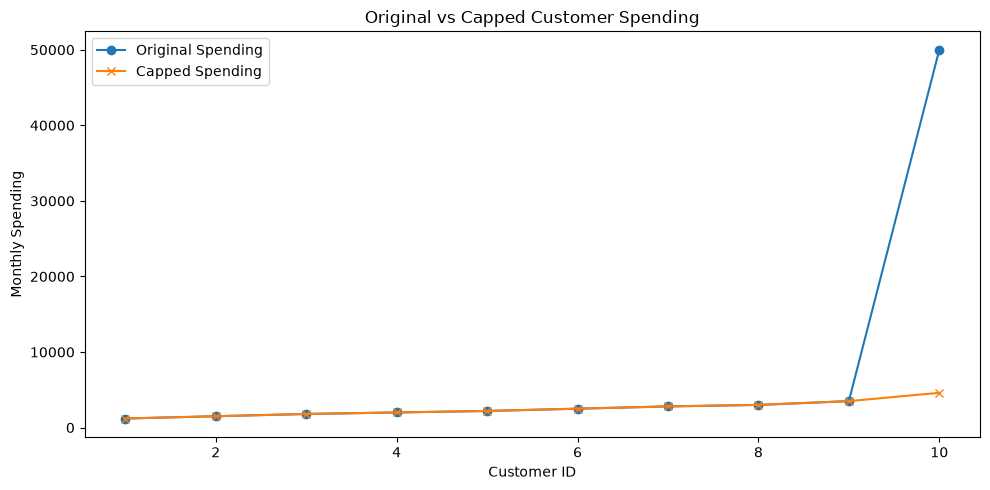


Potential Outliers Requiring Investigation:
   Customer_ID  Monthly_Spending  IQR_Outlier
9           10             50000         True


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats.mstats import winsorize

# Step 1: Create a sample customer spending dataset
df = pd.DataFrame({
    "Customer_ID": range(1, 11),
    "Monthly_Spending": [
        1200, 1500, 1800, 2000, 2200,
        2500, 2800, 3000, 3500, 50000
    ]
})

print("Original Dataset:")
print(df)

# Step 2: Calculate IQR boundaries
Q1 = df["Monthly_Spending"].quantile(0.25)
Q3 = df["Monthly_Spending"].quantile(0.75)
IQR = Q3 - Q1

lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

df["IQR_Outlier"] = (
    (df["Monthly_Spending"] < lower_iqr)
    | (df["Monthly_Spending"] > upper_iqr)
)

print("\nIQR Results:")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Boundary:", lower_iqr)
print("Upper Boundary:", upper_iqr)

# Step 3: Calculate Z-scores
mean_value = df["Monthly_Spending"].mean()
std_value = df["Monthly_Spending"].std()

if std_value != 0:
    df["Z_Score"] = (
        (df["Monthly_Spending"] - mean_value) / std_value
    )
    df["Z_Score_Outlier"] = df["Z_Score"].abs() > 3
else:
    df["Z_Score"] = 0.0
    df["Z_Score_Outlier"] = False

print("\nZ-Score Results:")
print(df[["Customer_ID", "Monthly_Spending", "Z_Score", "Z_Score_Outlier"]])

# Step 4: Detect outliers using percentiles
lower_percentile = df["Monthly_Spending"].quantile(0.01)
upper_percentile = df["Monthly_Spending"].quantile(0.99)

df["Percentile_Outlier"] = (
    (df["Monthly_Spending"] < lower_percentile)
    | (df["Monthly_Spending"] > upper_percentile)
)

print("\nPercentile Boundaries:")
print("1st Percentile:", lower_percentile)
print("99th Percentile:", upper_percentile)

# Step 5: Demonstrate capping using IQR boundaries
df["Capped_Spending"] = df["Monthly_Spending"].clip(
    lower=lower_iqr,
    upper=upper_iqr
)

# Step 6: Demonstrate flooring
# Example business rule: spending cannot be negative.
# This is a demonstration of a lower bound, not an outlier rule.
df["Floored_Spending"] = df["Monthly_Spending"].clip(lower=0)

# Step 7: Demonstrate Winsorization
# Limits are illustrative and are not universal recommendations.
df["Winsorized_Spending"] = np.asarray(
    winsorize(
        df["Monthly_Spending"].to_numpy(),
        limits=(0.0, 0.1)
    )
)

# Step 8: Demonstrate log transformation
df["Log_Spending"] = np.log1p(df["Monthly_Spending"])

# Step 9: Display the comparison
print("\nComparison of Outlier Treatments:")
print(
    df[
        [
            "Customer_ID",
            "Monthly_Spending",
            "IQR_Outlier",
            "Z_Score_Outlier",
            "Percentile_Outlier",
            "Capped_Spending",
            "Floored_Spending",
            "Winsorized_Spending",
            "Log_Spending"
        ]
    ]
)

# Step 10: Demonstrate removing flagged outliers
# This is for comparison only, not an automatic recommendation.
df_without_iqr_outliers = df.loc[~df["IQR_Outlier"]].copy()

print("\nDataset Shape Before Removal:", df.shape)
print("Dataset Shape After Removing IQR Outliers:",
      df_without_iqr_outliers.shape)

# Step 11: Plot the original and capped values
plt.figure(figsize=(10, 5))

plt.plot(
    df["Customer_ID"],
    df["Monthly_Spending"],
    marker="o",
    label="Original Spending"
)

plt.plot(
    df["Customer_ID"],
    df["Capped_Spending"],
    marker="x",
    label="Capped Spending"
)

plt.xlabel("Customer ID")
plt.ylabel("Monthly Spending")
plt.title("Original vs Capped Customer Spending")
plt.legend()
plt.tight_layout()
plt.show()

# Step 12: Display possible outliers for investigation
print("\nPotential Outliers Requiring Investigation:")
print(
    df.loc[
        df["IQR_Outlier"],
        ["Customer_ID", "Monthly_Spending", "IQR_Outlier"]
    ]
)